# Beyond top-30: predicting the score itself

"Top 30 of the day" is a convenient binary target but it throws away most of the information in
the outcome: a story that ends at 8 points and one that ends at 800 are both "not top 30" on a
busy day. Here the same features predict `log(1 + score at 24h)` directly. Two questions:

1. How well can the final score be predicted at 30 and 60 minutes?
2. Does ranking by predicted score recover the top-30 classifier's AUPRC? If so, one regression
   model serves every threshold, and the binary label was never needed.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score, confusion_matrix, mean_squared_error

from hn import dataset, evaluate, labels, models

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
xgb_params = json.load(open("xgb_params.json"))

In [2]:
rows, fits = [], {}
for t in [30, 60]:
    df = dataset.build(t, trajectory=True)
    train, test = dataset.temporal_split(df)
    cols = dataset.feature_columns(df)
    reg = models.make_pipeline(models.xgb_regressor(**xgb_params), cols).fit(train[cols], train.log_final_score)
    pred = reg.predict(test[cols])
    clf = models.make_pipeline(models.xgb_classifier(models.pos_weight(train.top30), **xgb_params), cols).fit(train[cols], train.top30)
    p_clf = clf.predict_proba(test[cols])[:, 1]
    fits[t] = (test, pred)
    rows.append({
        "t_min": t,
        "RMSE (log1p score)": round(np.sqrt(mean_squared_error(test.log_final_score, pred)), 3),
        "RMSE baseline (predict train mean)": round(np.sqrt(mean_squared_error(test.log_final_score, np.full(len(test), train.log_final_score.mean()))), 3),
        "Spearman": round(spearmanr(test.log_final_score, pred).statistic, 3),
        "top-30 AUPRC, ranking by predicted score": round(average_precision_score(test.top30, pred), 3),
        "top-30 AUPRC, dedicated classifier": round(average_precision_score(test.top30, p_clf), 3),
    })
pd.DataFrame(rows).set_index("t_min").T

t_min,30,60
RMSE (log1p score),0.739,0.574
RMSE baseline (predict train mean),0.995,1.000
Spearman,0.651,0.761
"top-30 AUPRC, ranking by predicted score",0.379,0.625
"top-30 AUPRC, dedicated classifier",0.326,0.584


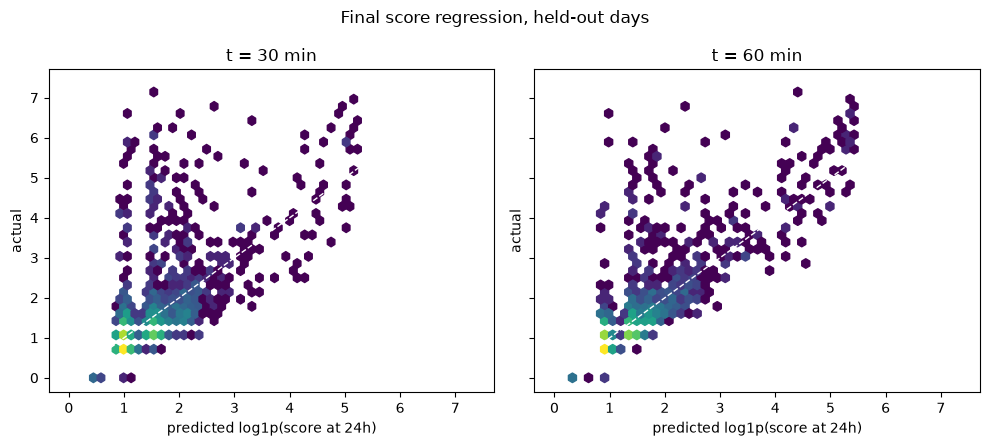

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, (t, (test, pred)) in zip(axes, fits.items()):
    ax.hexbin(pred, test.log_final_score, gridsize=35, bins="log", mincnt=1)
    lim = [0, max(test.log_final_score.max(), pred.max()) + 0.2]
    ax.plot(lim, lim, "w--", lw=1)
    ax.set(title=f"t = {t} min", xlabel="predicted log1p(score at 24h)", ylabel="actual")
fig.suptitle("Final score regression, held-out days"); fig.tight_layout()
fig.savefig(FIG / "score_regression.png", dpi=120, bbox_inches="tight")

## Four-tier view at t = 60

Bucket predicted and actual scores into the tiers used throughout: `<5`, `5-30`, `30-100`, `100+`.
Rows are actual, columns predicted. The interesting cells are the off-diagonal ones in the top-right
corner: stories that were quiet at 60 minutes and later took off.

In [4]:
test, pred = fits[60]
pred_tier = labels.tiers(pd.Series(np.expm1(pred), index=test.index))
cm = pd.DataFrame(confusion_matrix(test.tier, pred_tier, labels=range(4)), index=labels.TIER_NAMES, columns=labels.TIER_NAMES)
cm.index.name, cm.columns.name = "actual", "predicted"
cm

predicted,<5,5-30,30-100,100+
actual,,,,
<5,2013,70,0,0
5-30,134,194,11,0
30-100,20,27,20,5
100+,13,13,12,29


## Takeaway

- The final score is predictable from 30 minutes of observation to within a factor of about 2
  (RMSE 0.74 in log1p units, against 1.0 for predicting the mean), and the rank correlation rises
  from 0.65 at 30 minutes to 0.76 at 60.
- **Ranking by predicted score beats the dedicated top-30 classifier** at both observation times
  (0.38 vs 0.33 AUPRC at 30 minutes, 0.63 vs 0.58 at 60). The binary label throws away the
  ordering among the 97% of negatives, and that ordering is exactly what the model needs to learn
  what "taking off" looks like. One regression model serves every threshold.
- The confusion matrix shows where the remaining error lives: at 60 minutes, 13 of the 67 stories
  that finish above 100 points are still predicted to finish below 5. Those are the late bloomers
  that notebook 04 looks at.